# DCCM: Baseline vs PTR253 (KSHV SOX, 3POV)

Dynamic cross-correlation of Cα motions in the unphosphorylated (baseline) and phosphotyrosine 253 (PTR) systems, averaged over 3 replicas each.

- Trajectories are aligned on the same **stable core** as the RMSD/RMSF analysis (30% lowest-RMSF residues of baseline replica 1)
- Residue numbers follow the topology (+2 relative to the crystal structure)

Trajectories and topologies are not included in the repository.

In [ ]:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings("ignore")

## DCCM heatmaps

Average DCCM for baseline and PTR, and the difference (PTR − Baseline). The dashed line marks residue 253.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Stable core: 147 residues (threshold: 0.72 Å)
Computing Baseline DCCM...
Computing PTR DCCM...


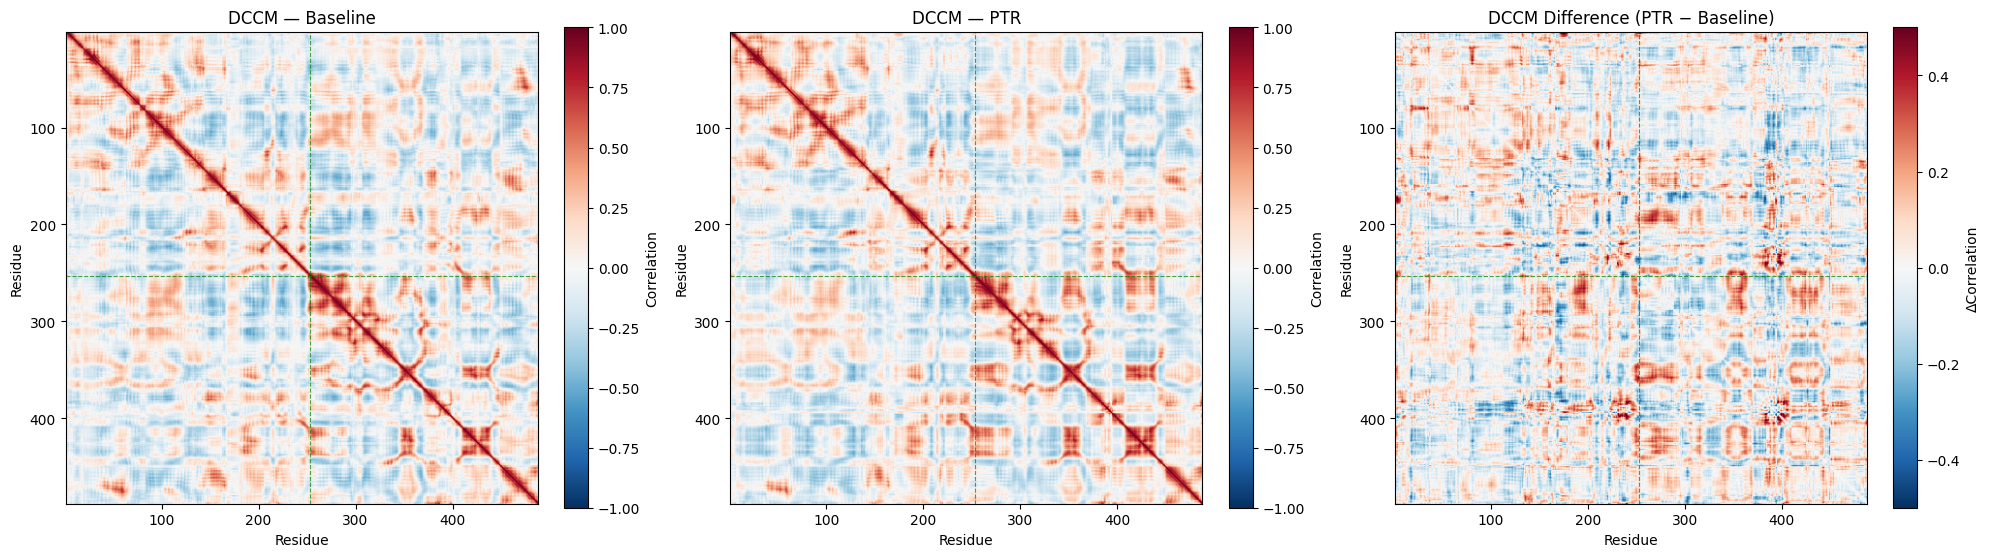

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import MDAnalysis as mda
from MDAnalysis.analysis import align
from MDAnalysis.analysis.rms import RMSF
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/3POV MD Sim"
ptr_top  = f"{BASE}/3POV/ptr.prmtop"
base_top = f"{BASE}/3POV/baseline.prmtop"
ptr_trajs  = [f"{BASE}/PTR_3POV_{i}/trajectory.dcd" for i in range(1, 4)]
base_trajs = [f"{BASE}/Baseline_3POV_{i}/trajectory.dcd" for i in range(1, 4)]

ca_sel = "(protein or resname PTR) and name CA"
bb_sel = "(protein or resname PTR) and backbone"


def find_stable_core(top, traj, percentile=30):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=bb_sel, in_memory=True).run()
    rmsf_vals = RMSF(ca).run().results.rmsf
    threshold = np.percentile(rmsf_vals, percentile)
    stable_resids = ca.resids[rmsf_vals <= threshold]
    core = " or ".join([f"resid {r}" for r in stable_resids])
    print(f"Stable core: {len(stable_resids)} residues (threshold: {threshold:.2f} Å)")
    return f"(protein or resname PTR) and backbone and ({core})"


def compute_dccm(top, traj, core_sel):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()

    positions = np.zeros((len(u.trajectory), len(ca), 3))
    for i, ts in enumerate(u.trajectory):
        positions[i] = ca.positions

    fluct = positions - positions.mean(axis=0)
    cov = np.einsum('fid,fjd->ij', fluct, fluct) / len(u.trajectory)
    diag = np.sqrt(np.diag(cov))
    return ca.resids, cov / np.outer(diag, diag)


shared_core = find_stable_core(base_top, base_trajs[0])

print("Computing Baseline DCCM...")
base_dccms = [compute_dccm(base_top, t, shared_core) for t in base_trajs]
print("Computing PTR DCCM...")
ptr_dccms = [compute_dccm(ptr_top, t, shared_core) for t in ptr_trajs]

resids = base_dccms[0][0]
base_stack = np.array([d[1] for d in base_dccms])
ptr_stack  = np.array([d[1] for d in ptr_dccms])

base_avg = base_stack.mean(axis=0)
ptr_avg  = ptr_stack.mean(axis=0)
base_sd  = base_stack.std(axis=0, ddof=1)
ptr_sd   = ptr_stack.std(axis=0, ddof=1)
diff     = ptr_avg - base_avg

# heatmaps
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
ext = [resids[0], resids[-1], resids[-1], resids[0]]
for ax, data, title in zip(axes[:2], [base_avg, ptr_avg], ["Baseline", "PTR"]):
    im = ax.imshow(data, cmap='RdBu_r', vmin=-1, vmax=1, extent=ext)
    ax.axhline(253, color='green', ls='--', lw=0.8, alpha=0.7)
    ax.axvline(253, color='green', ls='--', lw=0.8, alpha=0.7)
    ax.set_xlabel("Residue"); ax.set_ylabel("Residue"); ax.set_title(f"DCCM — {title}")
    plt.colorbar(im, ax=ax, fraction=0.046, label="Correlation")
im = axes[2].imshow(diff, cmap='RdBu_r', vmin=-0.5, vmax=0.5, extent=ext)
axes[2].axhline(253, color='green', ls='--', lw=0.8, alpha=0.7)
axes[2].axvline(253, color='green', ls='--', lw=0.8, alpha=0.7)
axes[2].set_xlabel("Residue"); axes[2].set_ylabel("Residue")
axes[2].set_title("DCCM Difference (PTR − Baseline)")
plt.colorbar(im, ax=axes[2], fraction=0.046, label="ΔCorrelation")
plt.tight_layout()
plt.savefig(f"{BASE}/dccm_comparison.png", dpi=300)
plt.show()

## Chord diagrams

Strong correlations (|r| ≥ 0.5, residues ≥ 4 apart) for each system, and the robust changes in the difference panel (|Δ| larger than the summed replica SDs and ≥ 0.35). Red = positive / strengthened, blue = negative / weakened.

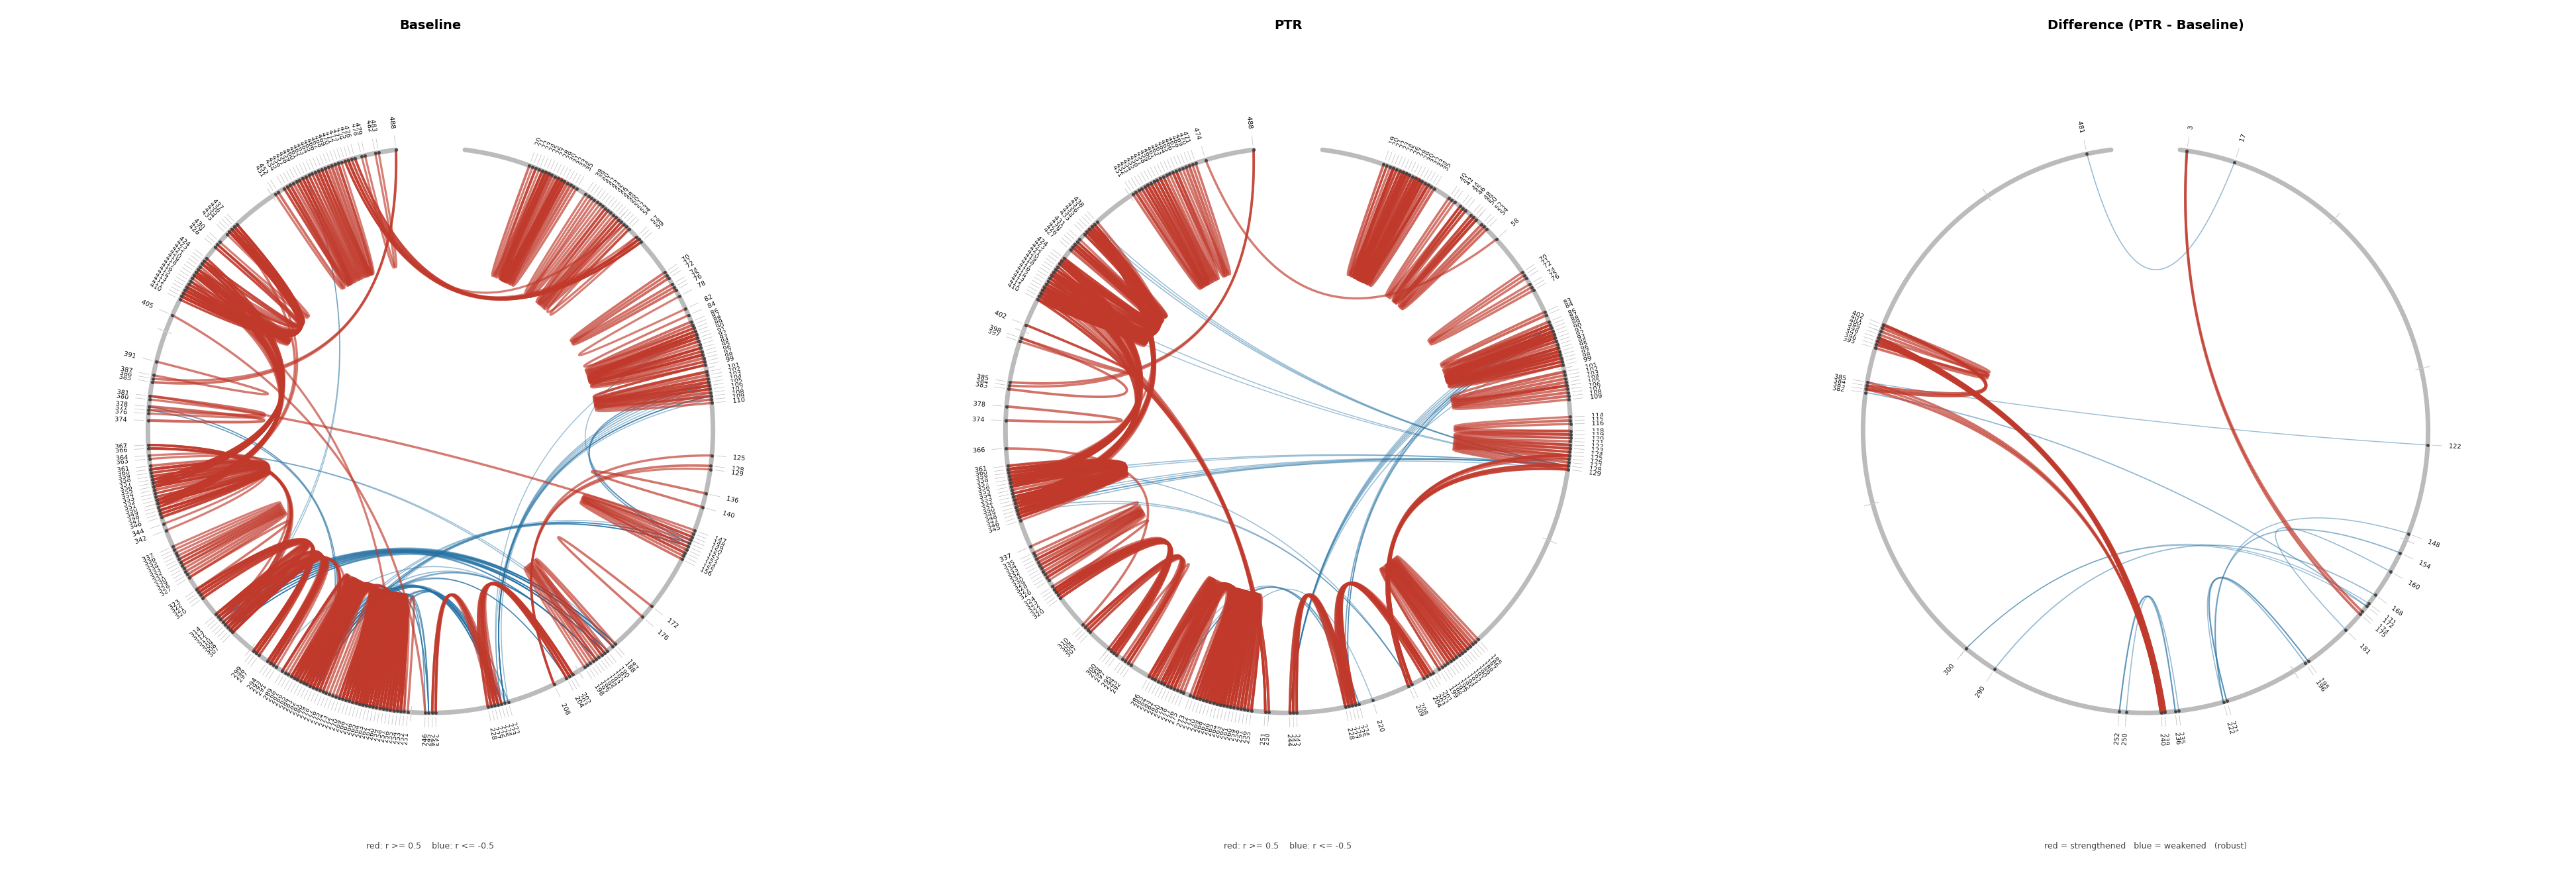

Baseline: 400 pos / 94 neg   |   PTR: 400 pos / 31 neg   |   Diff: 15 strengthened / 15 weakened


In [ ]:
import matplotlib.patheffects as pe


def strong_pairs(matrix, resids, seq_sep=4, pos_thresh=0.50, neg_thresh=-0.50, cap=400):
    ui, uj = np.triu_indices(len(resids), k=1)
    sep = np.abs(resids[ui] - resids[uj]) >= seq_sep
    ui, uj = ui[sep], uj[sep]
    v = matrix[ui, uj]

    def collect(mask):
        idx = np.where(mask)[0]
        pairs = [(resids[ui[k]], resids[uj[k]], v[k]) for k in idx]
        pairs.sort(key=lambda p: abs(p[2]), reverse=True)
        return pairs[:cap]

    return collect(v >= pos_thresh), collect(v <= neg_thresh)


def robust_extremes(diff, base_sd, ptr_sd, resids, n=15, seq_sep=4, min_delta=0.35):
    ui, uj = np.triu_indices(len(resids), k=1)
    keep = np.abs(resids[ui] - resids[uj]) >= seq_sep
    ui, uj = ui[keep], uj[keep]
    d = diff[ui, uj]
    m = (np.abs(d) > (base_sd[ui, uj] + ptr_sd[ui, uj])) & (np.abs(d) >= min_delta)
    ui, uj, d = ui[m], uj[m], d[m]
    inc = [(resids[ui[k]], resids[uj[k]], d[k]) for k in np.argsort(d)[::-1] if d[k] > 0][:n]
    dec = [(resids[ui[k]], resids[uj[k]], d[k]) for k in np.argsort(d) if d[k] < 0][:n]
    return inc, dec


def _panel(ax, pos, neg, title, sublabel, rmin, rmax, gap, tick_step):
    R = 1.0
    ang = lambda r: np.deg2rad(90 - gap/2 - (r - rmin)/(rmax - rmin) * (360 - gap))
    pt = lambda r, rad=R: np.array([rad*np.cos(ang(r)), rad*np.sin(ang(r))])

    pairs = pos + neg
    mags = [abs(v) for *_, v in pairs] or [1]
    vmin, vmax = min(mags), max(mags)
    lw = lambda v: 1.0 + 3.0 * (abs(v) - vmin) / (vmax - vmin + 1e-9)
    al = lambda v: 0.45 + 0.45 * (abs(v) - vmin) / (vmax - vmin + 1e-9)

    def chord(r1, r2, color, v):
        P1, P2 = pt(r1), pt(r2)
        C = 0.18 * (P1 + P2) / 2
        t = np.linspace(0, 1, 100)[:, None]
        B = (1-t)**2 * P1 + 2*(1-t)*t * C + t**2 * P2
        ax.plot(B[:, 0], B[:, 1], color=color, lw=lw(v), alpha=al(v),
                solid_capstyle="round", zorder=2)

    th = np.linspace(np.deg2rad(90-gap/2), np.deg2rad(90-gap/2-(360-gap)), 400)
    ax.plot(R*np.cos(th), R*np.sin(th), color="#bbb", lw=5, solid_capstyle="round", zorder=1)
    for r in range(tick_step, rmax, tick_step):
        pin, pout = pt(r, R*0.98), pt(r, R*1.03)
        ax.plot([pin[0], pout[0]], [pin[1], pout[1]], color="#ccc", lw=0.8)

    for a, b, v in neg:
        chord(a, b, "#2471a3", v)
    for a, b, v in pos:
        chord(a, b, "#c0392b", v)

    xs = sorted(set(x for p in pairs for x in p[:2]))
    for r in xs:
        ax.plot(*pt(r), "o", ms=2.5, color="#444", zorder=3)
        a_deg = np.rad2deg(ang(r))
        base, tip = pt(r, R*1.015), pt(r, R*1.05)
        ax.plot([base[0], tip[0]], [base[1], tip[1]], color="#bbb", lw=0.5, zorder=3)
        lp = pt(r, R*1.075)
        rot, ha = a_deg, "left"
        if 90 < (a_deg % 360) < 270:
            rot, ha = a_deg + 180, "right"
        ax.text(lp[0], lp[1], str(r), ha=ha, va="center", fontsize=7,
                rotation=rot, rotation_mode="anchor", color="#111", zorder=5,
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

    ax.text(0, 1.42, title, ha="center", fontsize=14, fontweight="bold")
    ax.text(0, -1.48, sublabel, ha="center", fontsize=9, color="#444")
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.55, 1.5)
    ax.set_aspect("equal"); ax.axis("off")


def plot_dccm_chords(base_avg, ptr_avg, diff, base_sd, ptr_sd, resids,
                     rmin=1, rmax=None, gap=14, tick_step=50,
                     pos_thresh=0.50, neg_thresh=-0.50, seq_sep=4, min_delta=0.35,
                     cap=400, outfile=f"{BASE}/dccm_chords_3panel_symmetric.png"):
    rmax = int(resids.max()) + 5 if rmax is None else rmax

    bpos, bneg = strong_pairs(base_avg, resids, seq_sep, pos_thresh, neg_thresh, cap)
    ppos, pneg = strong_pairs(ptr_avg, resids, seq_sep, pos_thresh, neg_thresh, cap)
    inc, dec = robust_extremes(diff, base_sd, ptr_sd, resids, seq_sep=seq_sep, min_delta=min_delta)

    sub = f"red: r >= {pos_thresh}    blue: r <= {neg_thresh}"
    fig, axes = plt.subplots(1, 3, figsize=(39, 14))
    _panel(axes[0], bpos, bneg, "Baseline", sub, rmin, rmax, gap, tick_step)
    _panel(axes[1], ppos, pneg, "PTR", sub, rmin, rmax, gap, tick_step)
    _panel(axes[2], inc, dec, "Difference (PTR - Baseline)",
           "red = strengthened   blue = weakened   (robust)",
           rmin, rmax, gap, tick_step)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Baseline: {len(bpos)} pos / {len(bneg)} neg   |   "
          f"PTR: {len(ppos)} pos / {len(pneg)} neg   |   "
          f"Diff: {len(inc)} strengthened / {len(dec)} weakened")


plot_dccm_chords(base_avg, ptr_avg, diff, base_sd, ptr_sd, resids,
                 rmin=1, rmax=488, pos_thresh=0.50, neg_thresh=-0.50)